Started on 2025 07 23 @ 02:33

In [1]:
# jupyter setup boilerplate
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.pyplot import *
import numpy as np


from fitting import *

import json
import datetime

from qualang_tools.plot import Fit

import pprint as pp

from plotting_helpers import *

%matplotlib inline
# from pnax_msmts import *
# from set_pulse_onoff import *
from malab import *

num_qubits = 8

No module named 'visa'
Warning VISA library import failed
Warning serial library import failed.
Could not load InstrumentManagerWindow
2025-08-23 17:43:05,518 - qm - INFO     - Starting session: bc018c54-a759-417b-bd0c-da81f5814523


# Plotting trial data

In [10]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz\fast flux crosstalk 1\5"
global_data_path = global_data_path + expt_path 

colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

q_times = np.linspace(-0.1, 22, 5) # in us
data_path = global_data_path + "\\"
data_files_array = []
for q in range(num_qubits):
    data_files = []
    q1 = 0
    date1 = '2025-07-23'
    # date2 = '2025-07-09' # use if two dates (overnight data)
    index_shift = 0
    for i in range(len(q_times)):
        try:
            temp_file = data_path + str(f"{i:05d}") + '_qubit_spec_ge_Q' + str(q1) + '_FF' + str(q) + '_' + date1 + '.h5'
            with SlabFile(temp_file, 'r') as f:
                data_files.append(temp_file)
        except:
            print("Cannot find file...")
    data_files_array.append(data_files)

print(data_files_array)



Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
[[], ['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00000_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00001_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00002_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00003_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5'], ['M:/malab/_Data/PUR1D4

['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00000_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00001_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00002_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00003_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\5\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5']
[3965.635418035036, 3971.203484495267, 3970.5370254669474, 3969.8978206919114, 3962.5385918414922]
['M:/malab/_Data/PUR1D4/202506

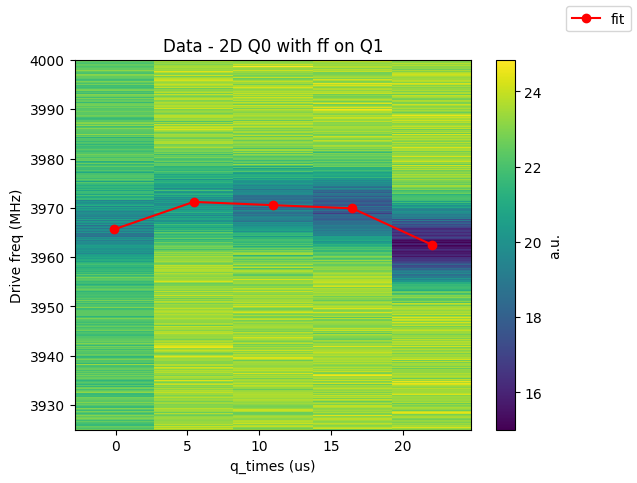

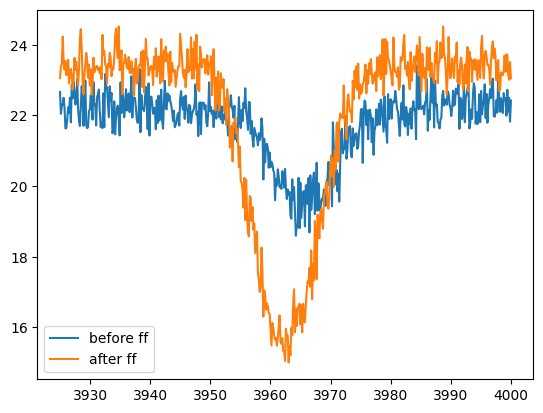

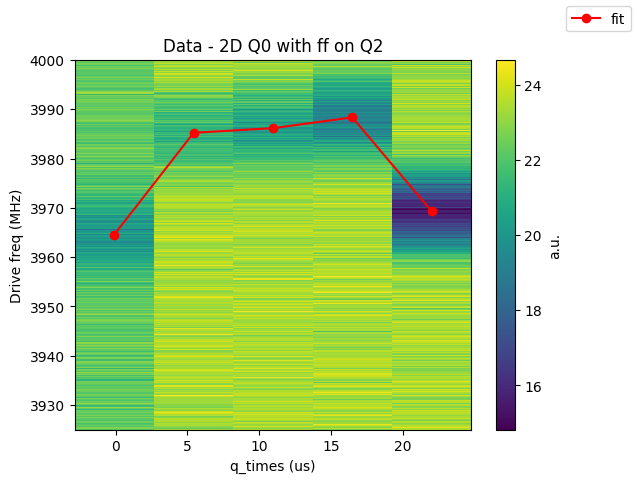

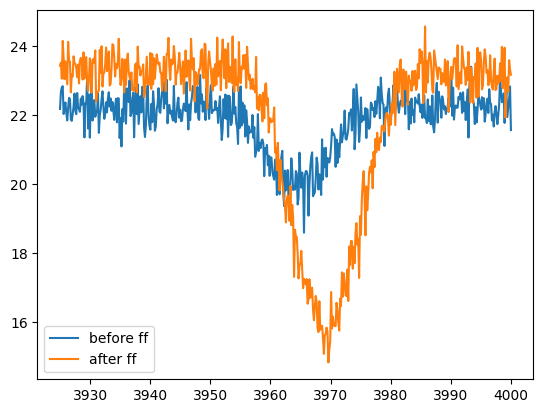

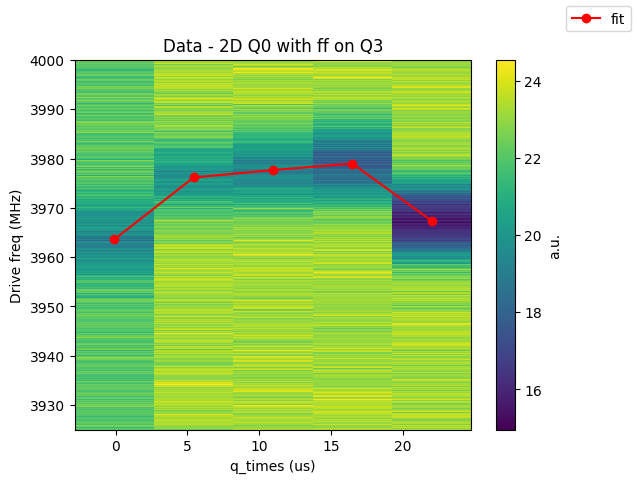

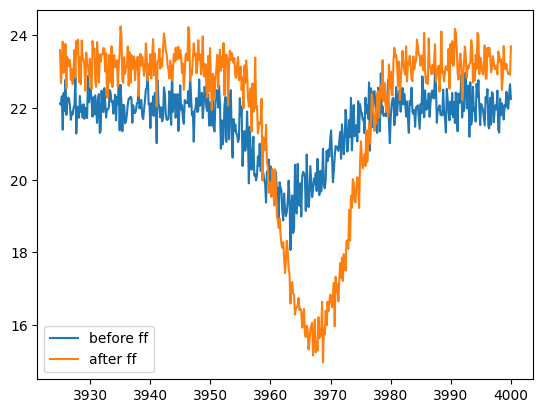

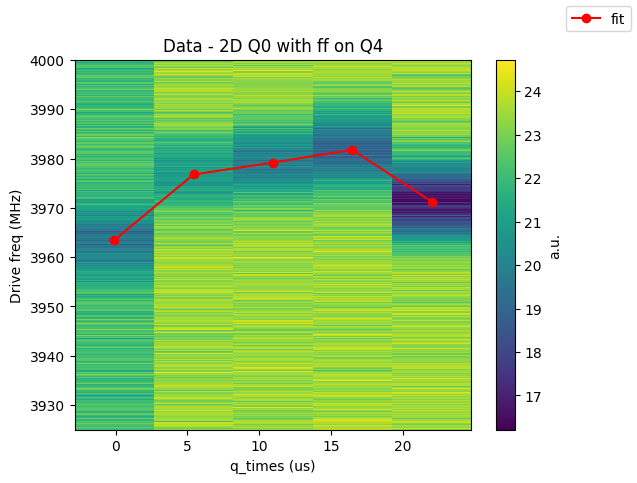

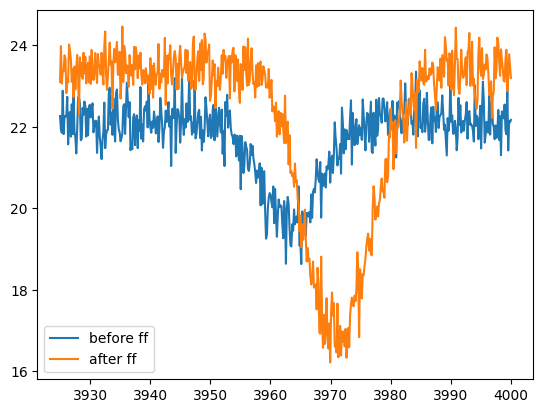

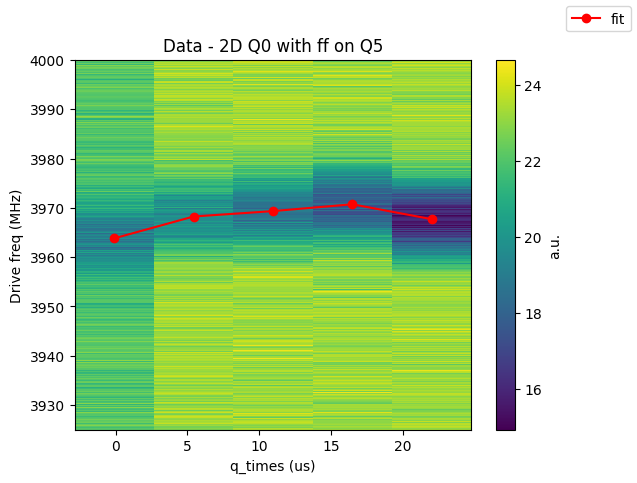

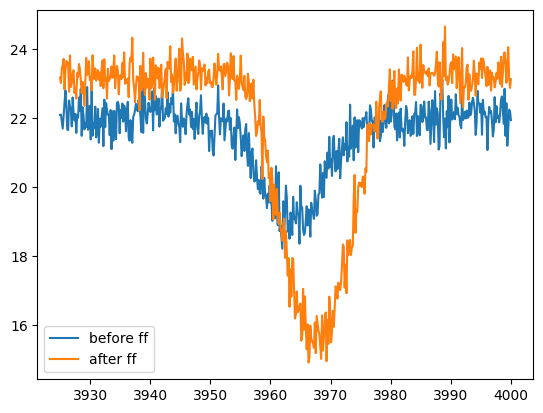

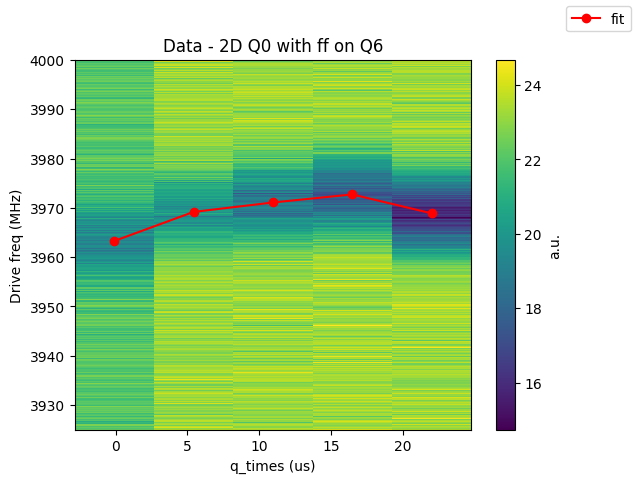

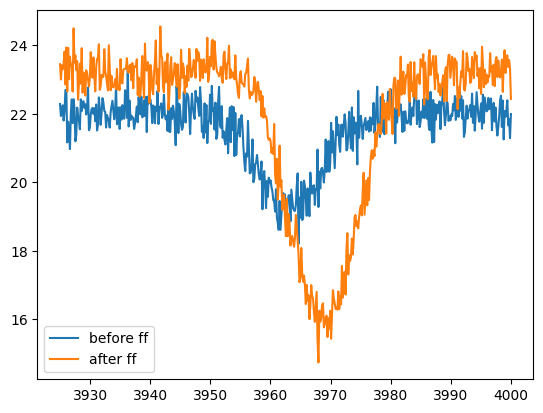

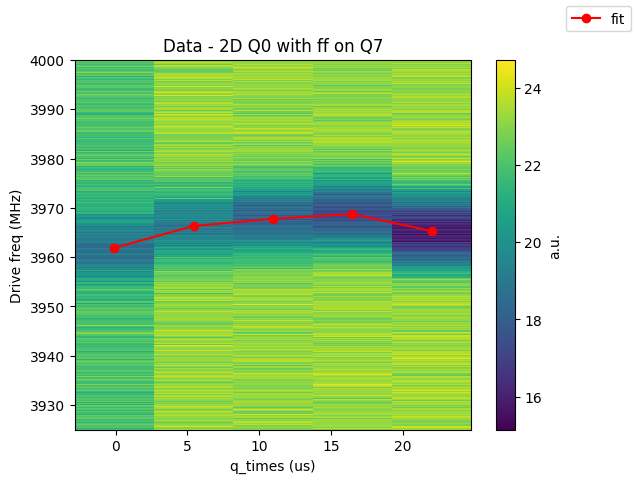

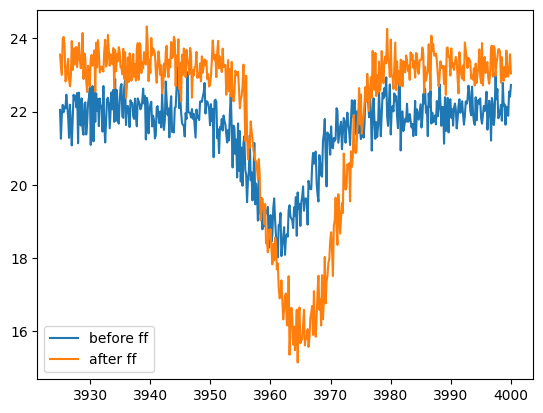

In [21]:
for j, data_files in enumerate(data_files_array[1:]):

    qubit_freqs = []
    freq_pts = []
    amp_pts = []

    for i, data in enumerate(data_files):
        with SlabFile(data, 'r') as f:
            freqs = array(f['fpts'])[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            # fit_result = f.attrs['fit_result']
            # fit_result = json.loads(fit_result)
            config = f.attrs['config']
            config = json.loads(config)
        freq_pts.append(freqs)
        amp_pts.append(amps)

        fits = fitlor(freqs,-amps,fitparams=None,showfit=False,showstartfit=False,debug=False)
        qubit_freqs.append(fits[2])
        # print(qubit_freqs)

    print(data_files)
    print(qubit_freqs)
    freq_pts = np.array(freq_pts)
    amp_pts = np.array(amp_pts)

    cmap = 'viridis'
    fig, ax = plt.subplots()
    colorplot = ax.pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax.set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax.set_ylabel('Drive freq (MHz)')
    ax.set_xlabel('q_times (us)')
    ax.plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    fig.legend()
    # ax.set_xlim(-1,1)
    ax.set_ylim(3925,4000)

    figure()
    plot(freq_pts[0], amp_pts[0], label='before ff')
    plot(freq_pts[-1], amp_pts[-1], label='after ff')
    legend()

In [26]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz\fast flux crosstalk 1\test"
global_data_path = global_data_path + expt_path 

colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

q_times = np.linspace(-1, 22, 5) # in us
data_path = global_data_path + "\\"
data_files_array = []
for q in range(num_qubits):
    data_files = []
    q1 = 0
    date1 = '2025-07-23'
    # date2 = '2025-07-09' # use if two dates (overnight data)
    index_shift = 0
    for i in range(len(q_times)):
        try:
            temp_file = data_path + str(f"{i:05d}") + '_qubit_spec_ge_Q' + str(q1) + '_FF' + str(q) + '_' + date1 + '.h5'
            with SlabFile(temp_file, 'r') as f:
                data_files.append(temp_file)
        except:
            print("Cannot find file...")
    data_files_array.append(data_files)

print(data_files_array)



Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
[[], ['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00000_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00001_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldo

['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00000_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00001_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00002_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00003_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5']
[3972.182351781943, 3971.291223989807, 3970.4599524975843, 3969.7103124021373, 3962.410285484659]
['M:/malab/_Data

ValueError: not enough values to unpack (expected 2, got 1)

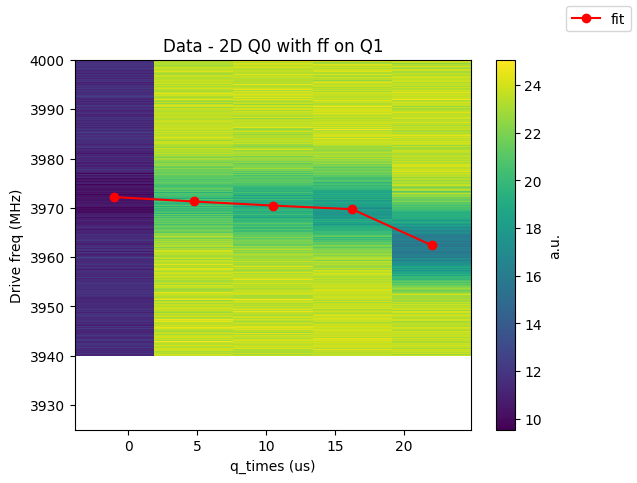

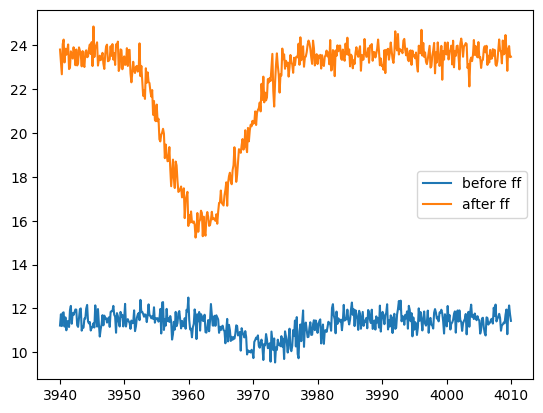

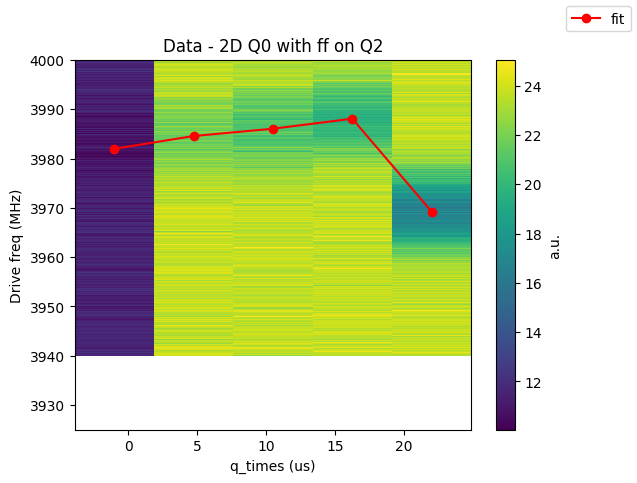

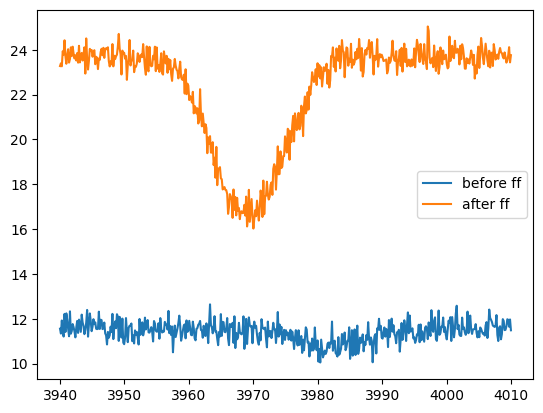

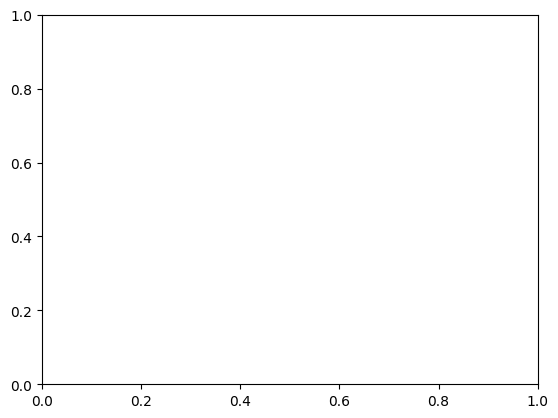

In [27]:
for j, data_files in enumerate(data_files_array[1:]):

    qubit_freqs = []
    freq_pts = []
    amp_pts = []

    for i, data in enumerate(data_files):
        with SlabFile(data, 'r') as f:
            freqs = array(f['fpts'])[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            # fit_result = f.attrs['fit_result']
            # fit_result = json.loads(fit_result)
            config = f.attrs['config']
            config = json.loads(config)
        freq_pts.append(freqs)
        amp_pts.append(amps)

        fits = fitlor(freqs,-amps,fitparams=None,showfit=False,showstartfit=False,debug=False)
        qubit_freqs.append(fits[2])
        # print(qubit_freqs)

    print(data_files)
    print(qubit_freqs)
    freq_pts = np.array(freq_pts)
    amp_pts = np.array(amp_pts)

    cmap = 'viridis'
    fig, ax = plt.subplots()
    colorplot = ax.pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax.set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax.set_ylabel('Drive freq (MHz)')
    ax.set_xlabel('q_times (us)')
    ax.plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    fig.legend()
    # ax.set_xlim(-1,1)
    ax.set_ylim(3925,4000)

    figure()
    plot(freq_pts[0], amp_pts[0], label='before ff')
    plot(freq_pts[-1], amp_pts[-1], label='after ff')
    legend()

In [36]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz\fast flux crosstalk 1\test"
global_data_path = global_data_path + expt_path 

colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

q_times = np.linspace(-1, 22, 5) # in us
data_path = global_data_path + "\\"
data_files_array = []
for q in range(num_qubits):
    data_files = []
    q1 = 0
    date1 = '2025-07-23'
    # date2 = '2025-07-09' # use if two dates (overnight data)
    index_shift = 4
    for i in range(len(q_times)):
        try:
            i+=index_shift
            temp_file = data_path + str(f"{i:05d}") + '_qubit_spec_ge_Q' + str(q1) + '_FF' + str(q) + '_' + date1 + '.h5'
            with SlabFile(temp_file, 'r') as f:
                data_files.append(temp_file)
        except:
            print("Cannot find file...")
    data_files_array.append(data_files)

print(data_files_array)



Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
[[], ['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00005_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubi

['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00005_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00006_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00007_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00008_qubit_spec_ge_Q0_FF1_2025-07-23.h5']
[3962.410285484659, 3972.821564142563, 3971.3977917714947, 3970.4345851396743, 3969.900328153198]
['M:/malab/_Data

TypeError: Dimensions of C (500, 1) should be one smaller than X(5) and Y(500) while using shading='flat' see help(pcolormesh)

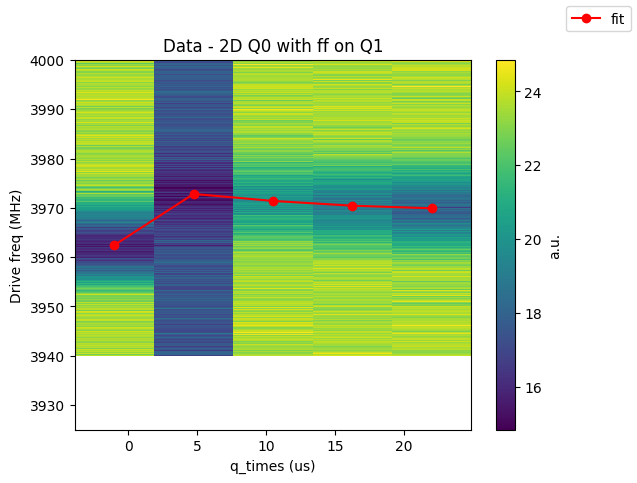

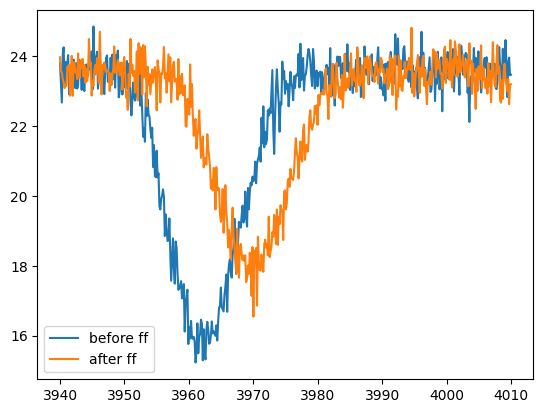

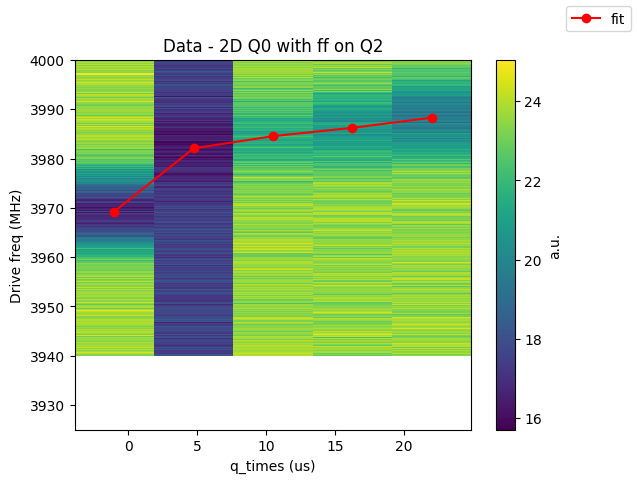

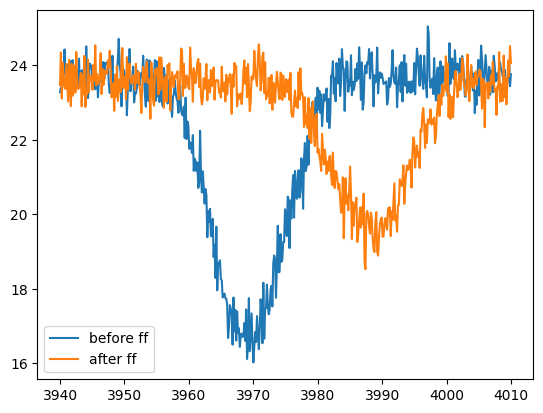

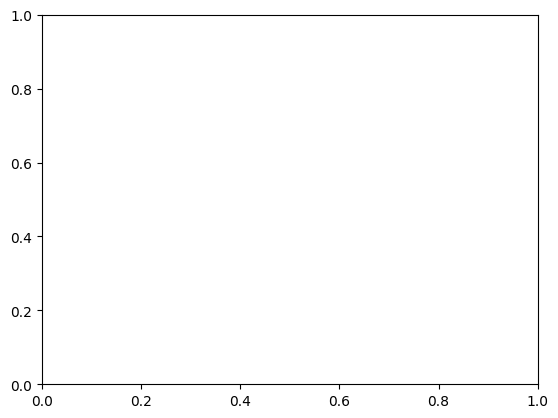

In [37]:
for j, data_files in enumerate(data_files_array[1:]):

    qubit_freqs = []
    freq_pts = []
    amp_pts = []

    for i, data in enumerate(data_files):
        with SlabFile(data, 'r') as f:
            freqs = array(f['fpts'])[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            # fit_result = f.attrs['fit_result']
            # fit_result = json.loads(fit_result)
            config = f.attrs['config']
            config = json.loads(config)
        freq_pts.append(freqs)
        amp_pts.append(amps)

        fits = fitlor(freqs,-amps,fitparams=None,showfit=False,showstartfit=False,debug=False)
        qubit_freqs.append(fits[2])
        # print(qubit_freqs)

    print(data_files)
    print(qubit_freqs)
    freq_pts = np.array(freq_pts)
    amp_pts = np.array(amp_pts)

    cmap = 'viridis'
    fig, ax = plt.subplots()
    colorplot = ax.pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax.set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax.set_ylabel('Drive freq (MHz)')
    ax.set_xlabel('q_times (us)')
    ax.plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    fig.legend()
    # ax.set_xlim(-1,1)
    ax.set_ylim(3925,4000)

    figure()
    plot(freq_pts[0], amp_pts[0], label='before ff')
    plot(freq_pts[-1], amp_pts[-1], label='after ff')
    legend()

In [42]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz\fast flux crosstalk 1\test"
global_data_path = global_data_path + expt_path 

colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

q_times = np.linspace(-1, 22, 5) # in us
data_path = global_data_path + "\\"
data_files_array = []
for q in range(num_qubits):
    data_files = []
    q1 = 0
    date1 = '2025-07-23'
    # date2 = '2025-07-09' # use if two dates (overnight data)
    index_shift = 9
    for i in range(len(q_times)):
        try:
            i+=index_shift
            temp_file = data_path + str(f"{i:05d}") + '_qubit_spec_ge_Q' + str(q1) + '_FF' + str(q) + '_' + date1 + '.h5'
            with SlabFile(temp_file, 'r') as f:
                data_files.append(temp_file)
        except:
            print("Cannot find file...")
    data_files_array.append(data_files)

print(data_files_array)



Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
[[], ['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00009_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00010_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldo

['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00009_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00010_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00011_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00012_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\test\\00013_qubit_spec_ge_Q0_FF1_2025-07-23.h5']
[3962.464270691579, 3972.776707275925, 3970.923619138833, 3970.4252014339086, 3969.6951305653274]
['M:/malab/_Data

ValueError: not enough values to unpack (expected 2, got 1)

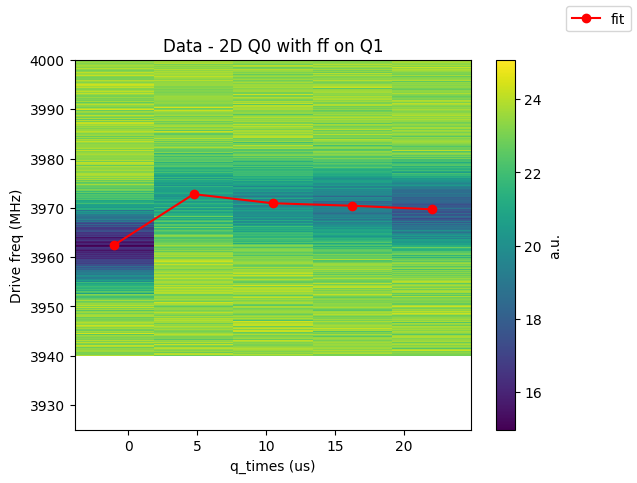

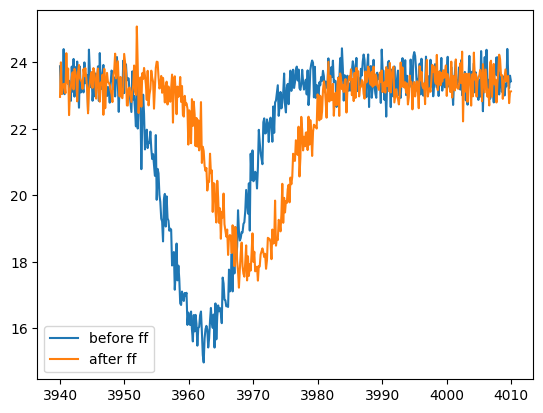

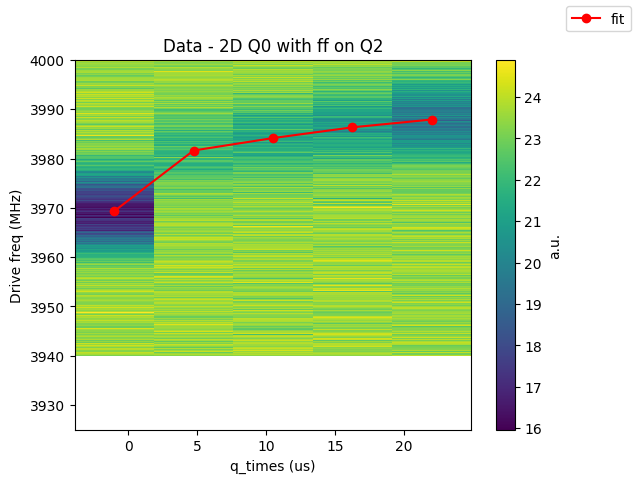

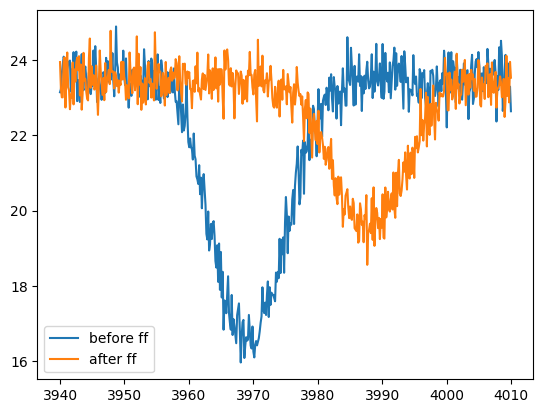

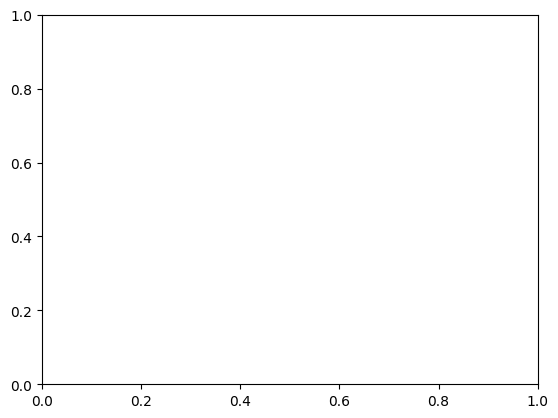

In [43]:
for j, data_files in enumerate(data_files_array[1:]):

    qubit_freqs = []
    freq_pts = []
    amp_pts = []

    for i, data in enumerate(data_files):
        with SlabFile(data, 'r') as f:
            freqs = array(f['fpts'])[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            # fit_result = f.attrs['fit_result']
            # fit_result = json.loads(fit_result)
            config = f.attrs['config']
            config = json.loads(config)
        freq_pts.append(freqs)
        amp_pts.append(amps)

        fits = fitlor(freqs,-amps,fitparams=None,showfit=False,showstartfit=False,debug=False)
        qubit_freqs.append(fits[2])
        # print(qubit_freqs)

    print(data_files)
    print(qubit_freqs)
    freq_pts = np.array(freq_pts)
    amp_pts = np.array(amp_pts)

    cmap = 'viridis'
    fig, ax = plt.subplots()
    colorplot = ax.pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax.set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax.set_ylabel('Drive freq (MHz)')
    ax.set_xlabel('q_times (us)')
    ax.plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    fig.legend()
    # ax.set_xlim(-1,1)
    ax.set_ylim(3925,4000)

    figure()
    plot(freq_pts[0], amp_pts[0], label='before ff')
    plot(freq_pts[-1], amp_pts[-1], label='after ff')
    legend()

In [16]:
freq_pts.shape

(5, 500)

In [ ]:
plot(freq_pts[0], amp_pts[0])

# Plotting data - Aug 23 2025

In [7]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\single qubit characterization 3.95 GHz\fast flux crosstalk 1\6"
global_data_path = global_data_path + expt_path 

colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

q_times = np.linspace(-1, 22, 50) # in us
data_path = global_data_path + "\\"
data_files_array = []
for q in range(num_qubits):
    data_files = []
    q1 = 0
    date1 = '2025-07-23'
    # date2 = '2025-07-09' # use if two dates (overnight data)
    index_shift = 0
    for i in range(len(q_times)):
        try:
            i+=index_shift
            temp_file = data_path + str(f"{i:05d}") + '_qubit_spec_ge_Q' + str(q1) + '_FF' + str(q) + '_' + date1 + '.h5'
            with SlabFile(temp_file, 'r') as f:
                data_files.append(temp_file)
        except:
            print("Cannot find file...")
    data_files_array.append(data_files)

print(data_files_array)



Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...
Cannot find file...


['M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6\\00000_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6\\00001_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6\\00002_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6\\00003_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6\\00004_qubit_spec_ge_Q0_FF1_2025-07-23.h5', 'M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\\qubit 0\\single qubit characterization 3.95 GHz\\fast flux crosstalk 1\\6

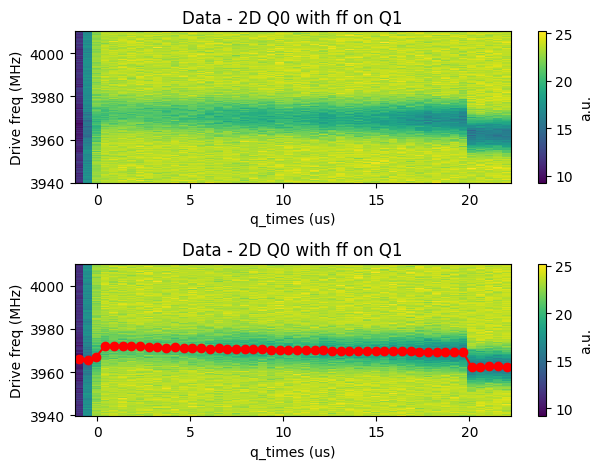

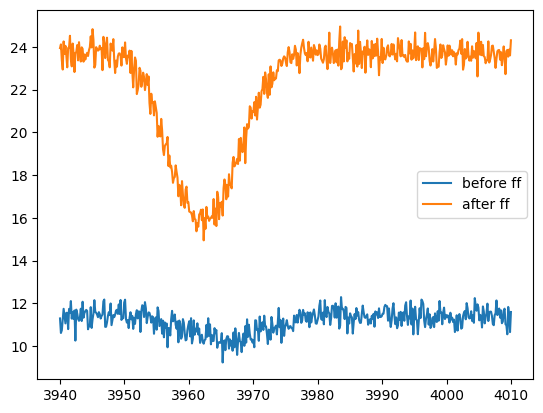

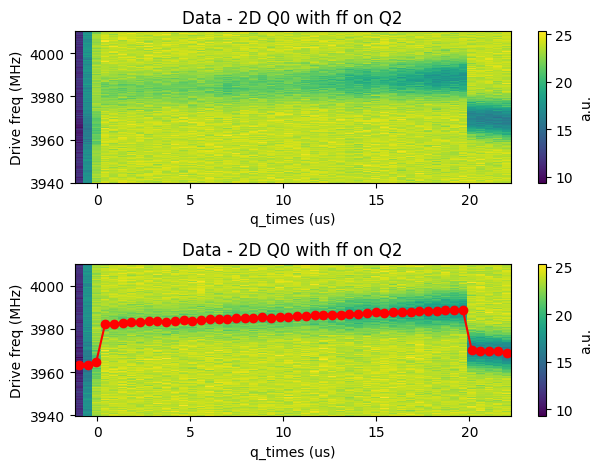

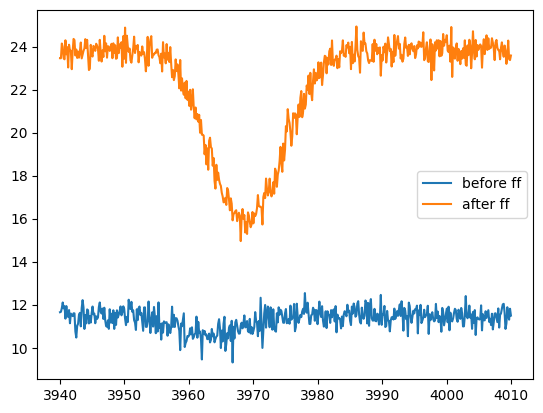

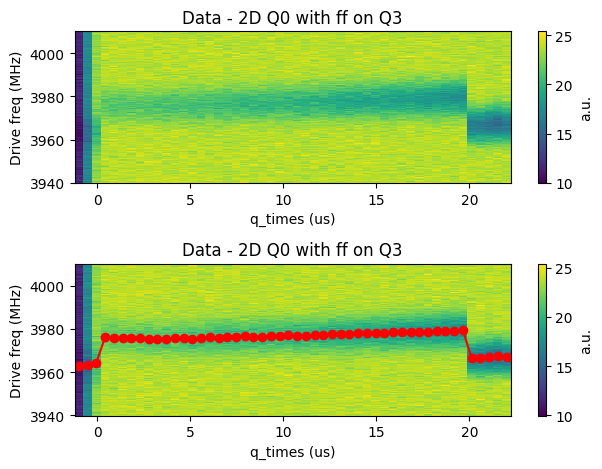

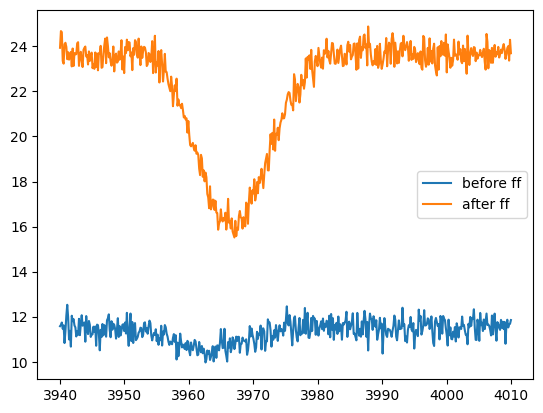

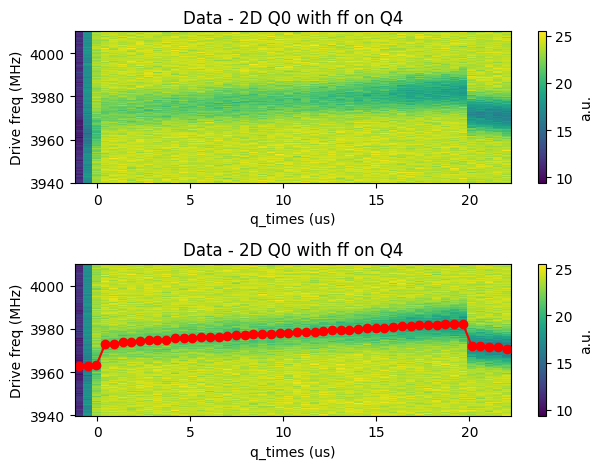

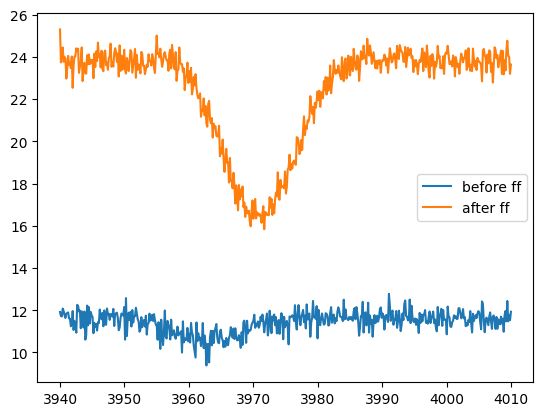

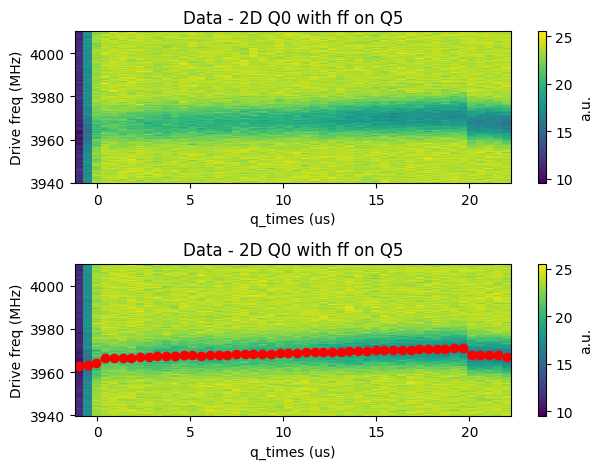

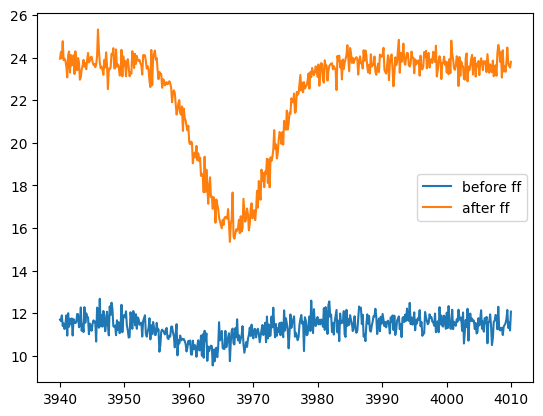

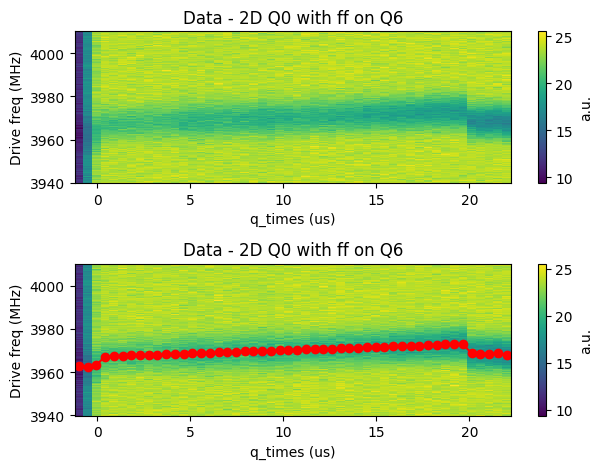

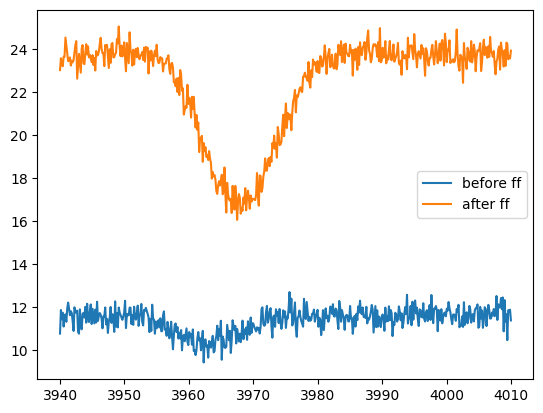

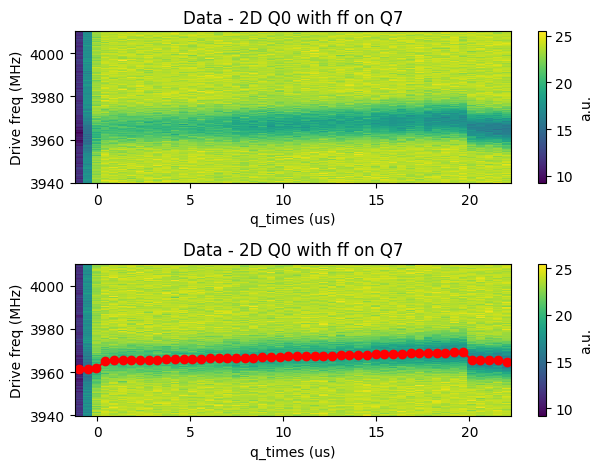

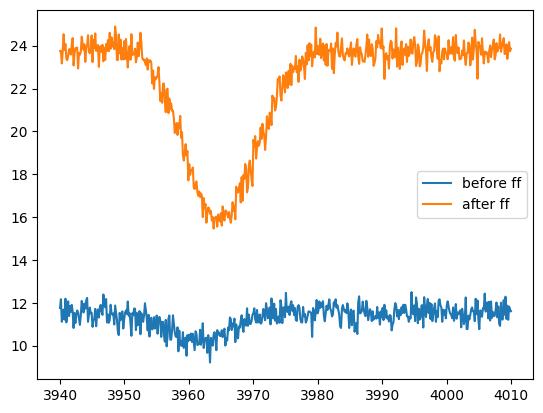

In [16]:
for j, data_files in enumerate(data_files_array[1:]):

    qubit_freqs = []
    freq_pts = []
    amp_pts = []

    for i, data in enumerate(data_files):
        with SlabFile(data, 'r') as f:
            freqs = array(f['fpts'])[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            q_times_array = array(f['q_time'])[0]
            # fit_result = f.attrs['fit_result']
            # fit_result = json.loads(fit_result)
            config = f.attrs['config']
            config = json.loads(config)
        freq_pts.append(freqs)
        amp_pts.append(amps)
        # print(q_times_array)

        fits = fitlor(freqs,-amps,fitparams=None,showfit=False,showstartfit=False,debug=False)
        qubit_freqs.append(fits[2])
        # print(qubit_freqs)

    print(data_files)
    print(qubit_freqs)
    freq_pts = np.array(freq_pts)
    amp_pts = np.array(amp_pts)

    cmap = 'viridis'
    fig, ax = plt.subplots(2)
    colorplot = ax[0].pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax[0].set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax[0].set_ylabel('Drive freq (MHz)')
    ax[0].set_xlabel('q_times (us)')
    # ax[0].plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    # fig.legend()

    colorplot = ax[1].pcolormesh(q_times, freq_pts.T, amp_pts.T, cmap = cmap)#, vmax = 7, vmin=5)
    plt.colorbar(colorplot, label='a.u.')
    ax[1].set_title('Data - 2D Q' + str(q1) + ' with ff on Q' + str(j+1))
    ax[1].set_ylabel('Drive freq (MHz)')
    ax[1].set_xlabel('q_times (us)')
    ax[1].plot(q_times, qubit_freqs, marker='o', color='r', label='fit')
    # fig.legend()
    # ax.set_xlim(-1,1)
    # ax.set_ylim(3925,4000)

    plt.tight_layout() 

    figure()
    plot(freq_pts[0], amp_pts[0], label='before ff')
    plot(freq_pts[-1], amp_pts[-1], label='after ff')
    legend()